### Machine Learning - Assignment 1: Unsupervised Learning | Exercise 3

In [16]:
import matplotlib.pyplot as plt
import numpy as np
from collections import deque

The third column of `data.csv` is the true label (1 or 2). DBSCAN is unsupervised, so it must only see the `x, y` coordinates —
the label is kept aside and used only at the end for comparison.

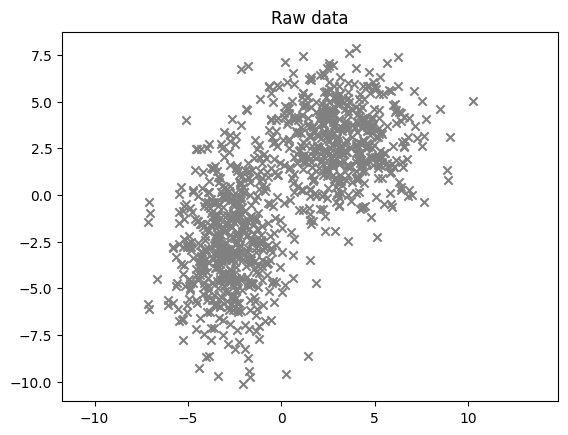

In [17]:
points = np.genfromtxt('data.csv', delimiter=',')

X = points[:, :2]                 # coordinates only, used by DBSCAN
label = points[:, 2].astype(int)  # true label, NOT used by DBSCAN

plt.scatter(X[:, 0], X[:, 1], marker="x", c="grey")
plt.axis("equal")
plt.title("Raw data")
plt.show()

#### The algorithm (as in the StatQuest video)

1. **Count neighbours**: for every point, count how many points lie inside a circle of radius `epsilon` around it.
2. **Core points**: a point is a *core point* if that circle contains at least `minimum_points` points (the point itself included).
   All other points are *non-core*.
3. **Start a cluster**: pick a random core point that does not belong to a cluster yet and give it a new cluster id.
4. **Grow the cluster**:
   - every **core** point close to a core point already in the cluster joins the cluster **and keeps extending it**;
   - every **non-core** point close to a core point of the cluster joins the cluster too (border point) **but does not extend it**.
5. When the cluster cannot grow anymore, go back to step 3 with the remaining core points.
6. When no unassigned core points are left, every point that is still not in a cluster is an **outlier (noise)**.

The function below implements these steps and stores a snapshot of the state every time one core point is used to
extend a cluster, so that the process can be shown afterwards.

In [18]:
def run_dbscan(X, epsilon, minimum_points):
    n = len(X)

    # 1. neighbours of each point (distance <= epsilon, the point itself included)
    distances = np.linalg.norm(X[:, None, :] - X[None, :, :], axis=2)
    neighbors = [np.where(distances[i] <= epsilon)[0] for i in range(n)]

    # 2. core points
    is_core = np.array([len(neighbors[i]) >= minimum_points for i in range(n)])

    labels = np.full(n, -1)  # -1 = not in a cluster (yet)
    history = []             # snapshots: (cluster id, point being expanded, labels at that moment)
    cluster_id = 0

    # 3. pick random unassigned core points to start new clusters
    for start in np.random.permutation(n):
        if not is_core[start] or labels[start] != -1:
            continue

        labels[start] = cluster_id
        history.append((cluster_id, start, labels.copy()))
        queue = deque([start])  # core points of this cluster that still have to extend it

        # 4. grow the cluster
        while queue:
            current = queue.popleft()
            for neighbor in neighbors[current]:
                if labels[neighbor] != -1:
                    continue
                labels[neighbor] = cluster_id
                if is_core[neighbor]:
                    queue.append(neighbor)  # core point -> keeps extending the cluster
                # non-core point -> joins the cluster but is NOT added to the queue
            history.append((cluster_id, current, labels.copy()))

        # 5. cluster finished, next one
        cluster_id += 1

    # 6. points still with label -1 are outliers
    return labels, is_core, neighbors, history

In [19]:
cluster_colors = ["tab:red", "tab:blue", "tab:green", "tab:orange", "tab:purple", "tab:brown", "tab:pink", "tab:olive"]

def plot_state(ax, X, labels, is_core, title, current=None, epsilon=None):
    unassigned = labels == -1
    # points not in a cluster (yet): core = grey dot, non-core = grey x
    ax.scatter(X[unassigned & is_core, 0], X[unassigned & is_core, 1], c="lightgrey", s=12)
    ax.scatter(X[unassigned & ~is_core, 0], X[unassigned & ~is_core, 1], c="grey", marker="x", s=12)
    # points in a cluster: core = dot, border (non-core) = x
    for c in np.unique(labels[~unassigned]):
        color = cluster_colors[c % len(cluster_colors)]
        in_c = labels == c
        ax.scatter(X[in_c & is_core, 0], X[in_c & is_core, 1], c=color, s=12)
        ax.scatter(X[in_c & ~is_core, 0], X[in_c & ~is_core, 1], c=color, marker="x", s=25, linewidths=1.5)
    # point currently extending the cluster and its epsilon circle
    if current is not None:
        ax.scatter(*X[current], c="black", marker="*", s=200, zorder=5)
        ax.add_patch(plt.Circle(X[current], epsilon, fill=False, color="black", lw=1.5, zorder=5))
    ax.set_title(title, fontsize=10)
    ax.set_aspect("equal")

#### Parameters

`epsilon = 0.7` and `minimum_points = 12`. With these values the low-density "bridge" between the two groups is not dense
enough to connect them, so DBSCAN finds two clusters (a smaller `epsilon` / larger `minimum_points` splits more, the opposite merges —
see the last section).

In [20]:
np.random.seed(42)

epsilon = 0.7
minimum_points = 12

labels, is_core, neighbors, history = run_dbscan(X, epsilon, minimum_points)

n_clusters = labels.max() + 1
print(f"clusters found: {n_clusters}")
for c in range(n_clusters):
    print(f"  cluster {c + 1}: {np.sum(labels == c)} points ({np.sum((labels == c) & is_core)} core, {np.sum((labels == c) & ~is_core)} border)")
print(f"outliers: {np.sum(labels == -1)}")
print(f"snapshots stored: {len(history)}")

clusters found: 2
  cluster 1: 360 points (296 core, 64 border)
  cluster 2: 407 points (335 core, 72 border)
outliers: 233
snapshots stored: 633


#### Snapshot 1 — Counting neighbours and finding core points

Left: a point with enough neighbours inside its `epsilon` circle (green, core) and one with just too few (red, non-core).
Right: all points classified — **dots are core points**, **x are non-core points**.

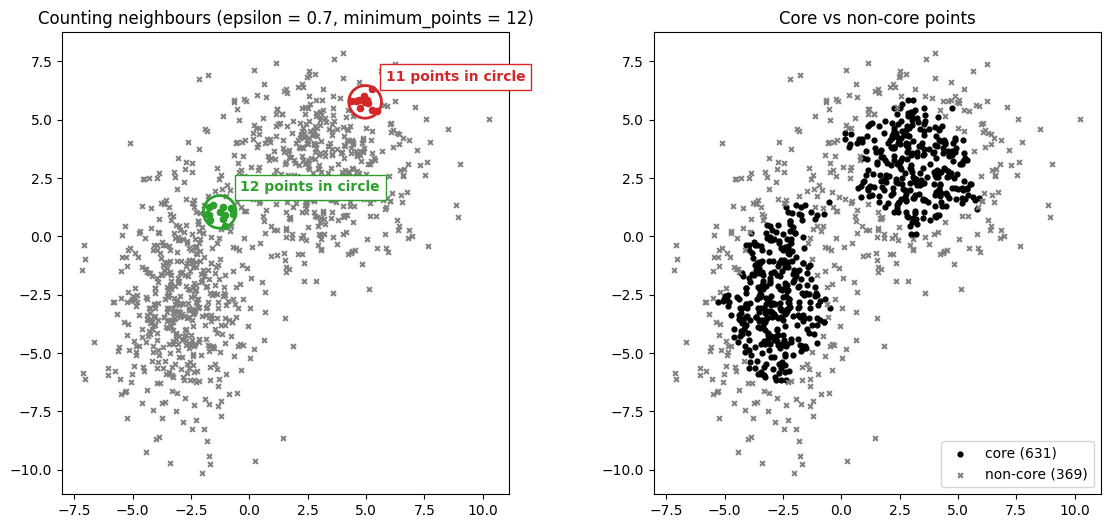

In [21]:
neighbor_count = np.array([len(nb) for nb in neighbors])
# examples close to the threshold: a core point with few neighbours and a non-core point with many
example_core = np.where(is_core)[0][np.argmin(neighbor_count[is_core])]
example_non_core = np.where(~is_core)[0][np.argmax(neighbor_count[~is_core])]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax = axes[0]
ax.scatter(X[:, 0], X[:, 1], c="grey", marker="x", s=12)
for i, color in [(example_core, "tab:green"), (example_non_core, "tab:red")]:
    ax.scatter(X[neighbors[i], 0], X[neighbors[i], 1], c=color, s=20)
    ax.add_patch(plt.Circle(X[i], epsilon, fill=False, color=color, lw=2))
    ax.annotate(f"{len(neighbors[i])} points in circle", X[i], xytext=(15, 15), textcoords="offset points", color=color, fontweight="bold",
                bbox=dict(facecolor="white", edgecolor=color))
ax.set_title(f"Counting neighbours (epsilon = {epsilon}, minimum_points = {minimum_points})")
ax.set_aspect("equal")

ax = axes[1]
ax.scatter(X[is_core, 0], X[is_core, 1], c="black", s=12, label=f"core ({is_core.sum()})")
ax.scatter(X[~is_core, 0], X[~is_core, 1], c="grey", marker="x", s=12, label=f"non-core ({(~is_core).sum()})")
ax.set_title("Core vs non-core points")
ax.set_aspect("equal")
ax.legend()

plt.show()

#### Snapshot 2 — Growing the first cluster

A random core point (black star) starts cluster 1. Each panel shows the cluster after more core points have extended it;
the black star and circle mark the core point extending the cluster at that moment.
Coloured dots are core points of the cluster, coloured **x** are non-core points that were absorbed (border points) — they
belong to the cluster but never extend it. Grey points are not assigned yet.

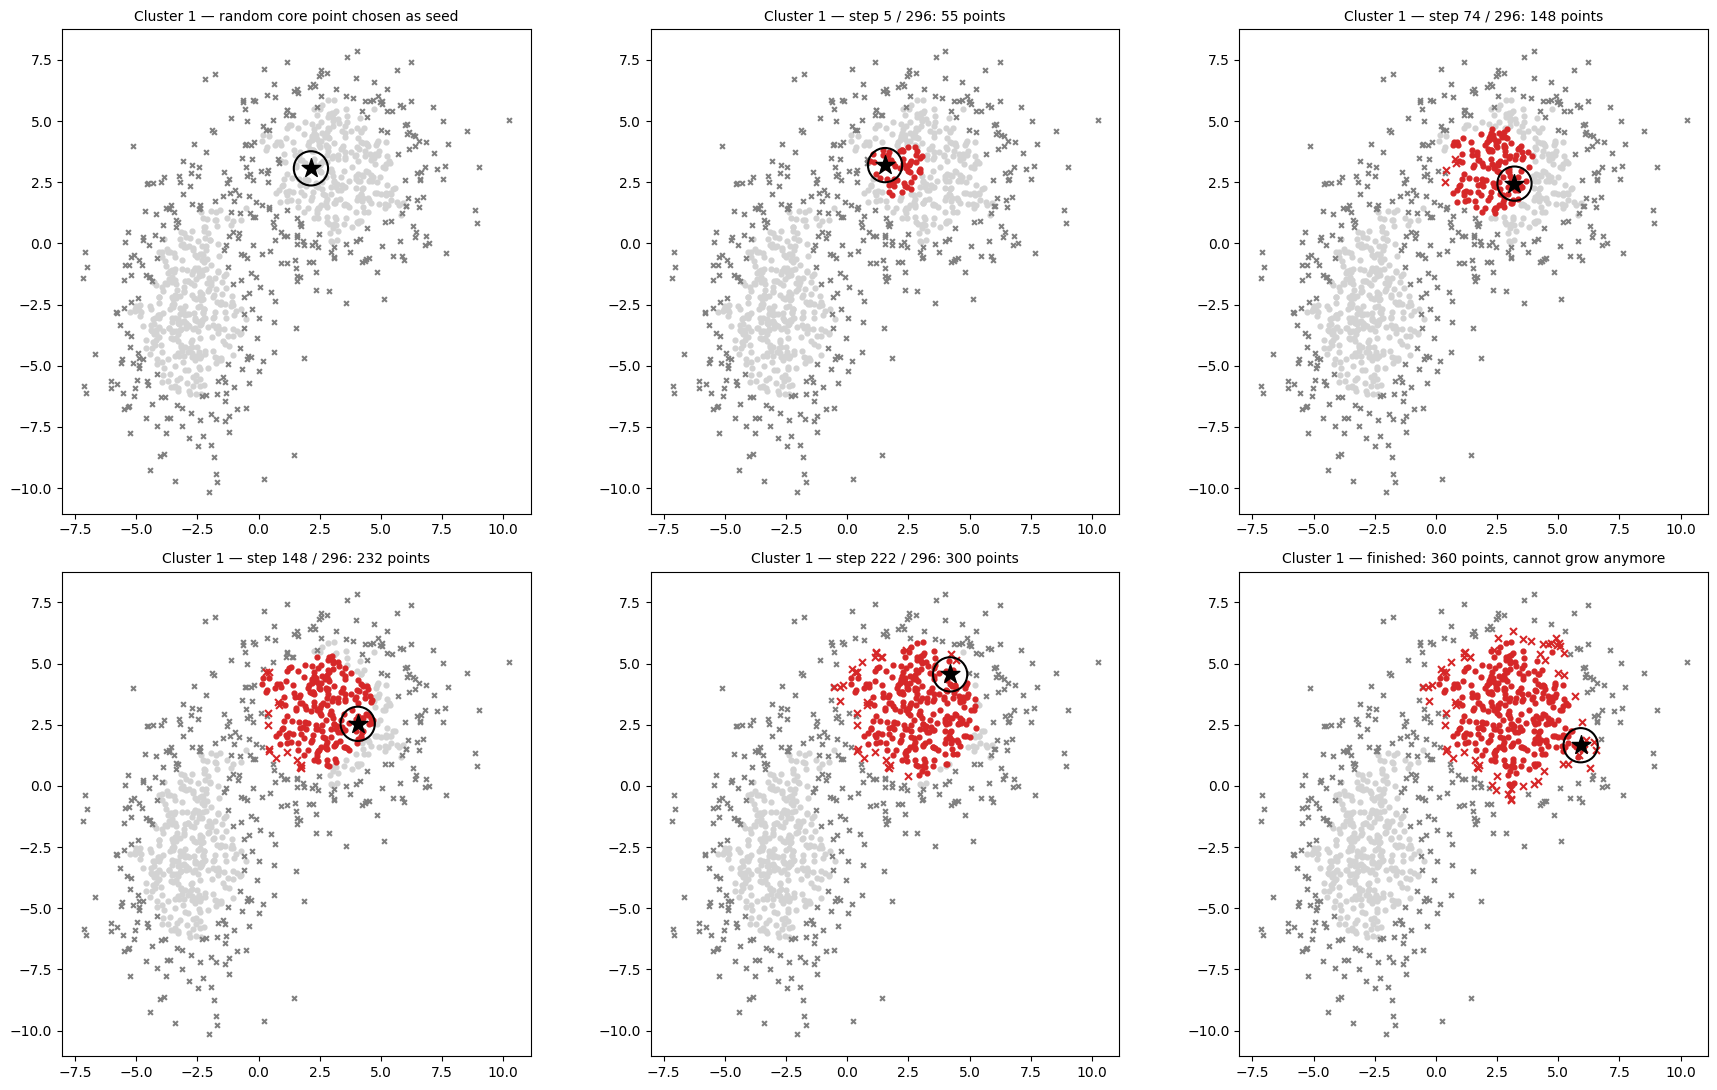

In [22]:
def plot_cluster_growth(cluster):
    steps = [i for i, (c, _, _) in enumerate(history) if c == cluster]
    # first step, a few intermediate ones, last step
    picks = [steps[0], steps[min(5, len(steps) - 1)], steps[len(steps) // 4], steps[len(steps) // 2], steps[3 * len(steps) // 4], steps[-1]]

    fig, axes = plt.subplots(2, 3, figsize=(18, 11))
    for ax, k in zip(axes.flat, picks):
        c, current, snapshot = history[k]
        n_in = np.sum(snapshot == c)
        title = f"Cluster {c + 1} — step {k - steps[0]} / {len(steps) - 1}: {n_in} points"
        if k == steps[0]:
            title = f"Cluster {c + 1} — random core point chosen as seed"
        if k == steps[-1]:
            title = f"Cluster {c + 1} — finished: {n_in} points, cannot grow anymore"
        plot_state(ax, X, snapshot, is_core, title, current=current, epsilon=epsilon)
    plt.tight_layout()
    plt.show()

plot_cluster_growth(0)

Cluster 1 stops growing when none of its core points has an unassigned point inside its `epsilon` circle. The points
between the two groups are too sparse to be core points, so they can be absorbed as border points but they never carry the
cluster across the gap.

#### Snapshot 3 — Growing the second cluster

The algorithm now picks another random core point that is not in any cluster yet and repeats the same process.

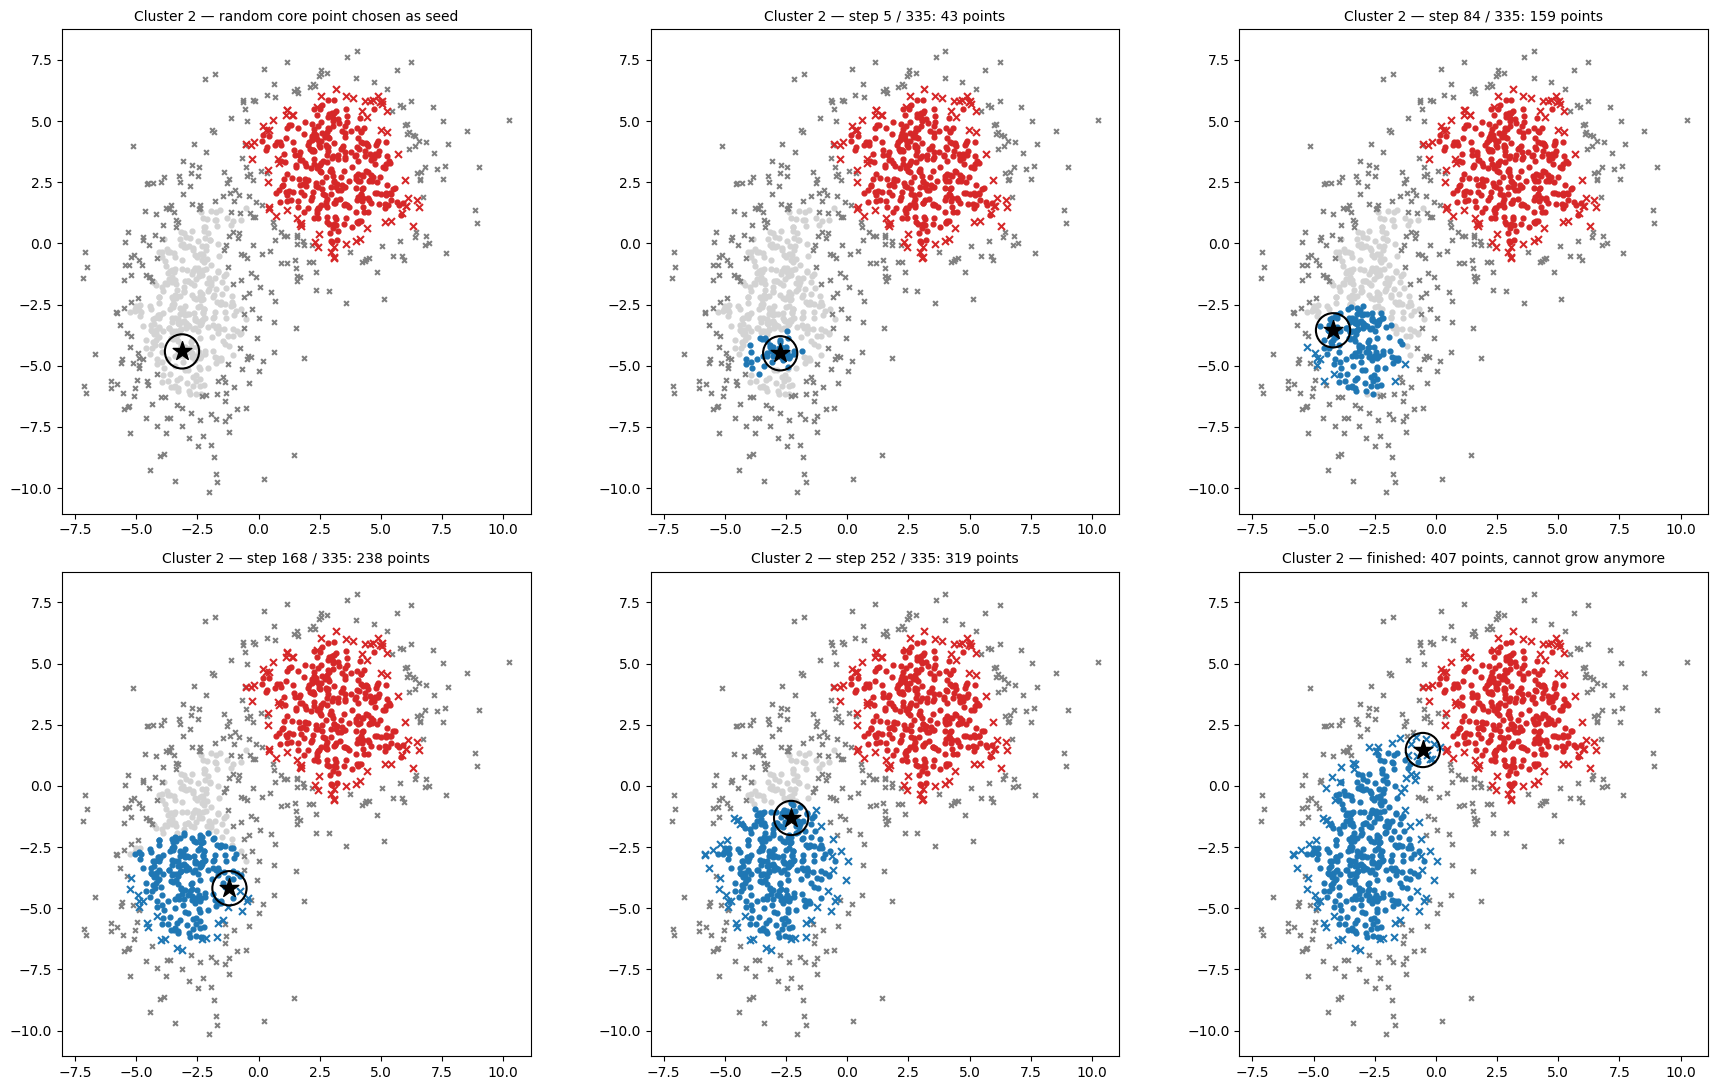

In [23]:
plot_cluster_growth(1)

#### Snapshot 4 — Final result

No unassigned core points are left, so the algorithm stops. All points that were never reached by a cluster are
**outliers** (black). On the right, the true labels for comparison.

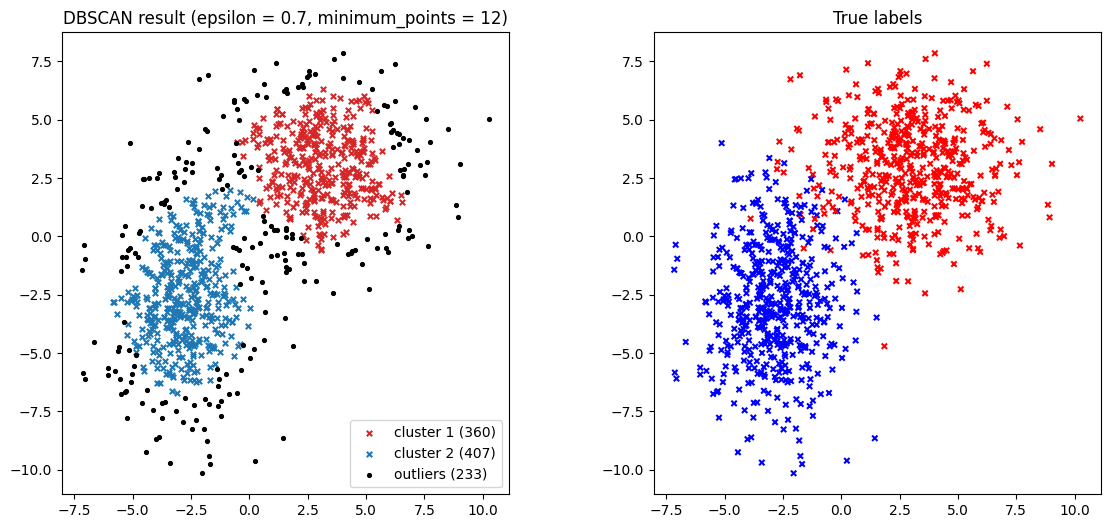

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax = axes[0]
for c in range(n_clusters):
    color = cluster_colors[c % len(cluster_colors)]
    ax.scatter(X[labels == c, 0], X[labels == c, 1], c=color, marker="x", s=15, label=f"cluster {c + 1} ({np.sum(labels == c)})")
ax.scatter(X[labels == -1, 0], X[labels == -1, 1], c="black", marker=".", s=30, label=f"outliers ({np.sum(labels == -1)})")
ax.set_title(f"DBSCAN result (epsilon = {epsilon}, minimum_points = {minimum_points})")
ax.set_aspect("equal")
ax.legend()

ax = axes[1]
colors = np.array(["red", "blue"])
ax.scatter(X[:, 0], X[:, 1], c=colors[label - 1], marker="x", s=15)
ax.set_title("True labels")
ax.set_aspect("equal")

plt.show()

#### Effect of the parameters

DBSCAN is sensitive to `epsilon` and `minimum_points`. With a larger `epsilon` (or smaller `minimum_points`) the
points in the region between the two groups become core points, forming a dense "bridge" — the two groups are then
merged into a single cluster. With a smaller `epsilon` the clusters break into many small pieces and many points become outliers.

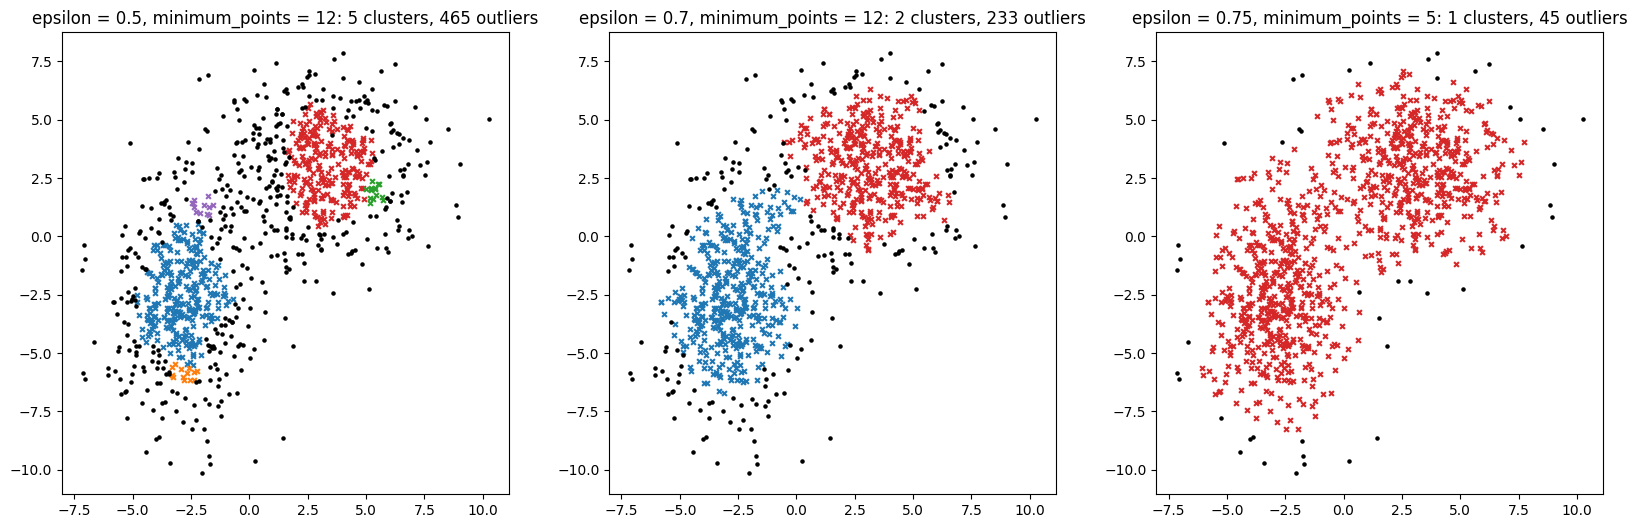

In [25]:
settings = [(0.5, 12), (0.7, 12), (0.75, 5)]

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, (eps, min_pts) in zip(axes, settings):
    np.random.seed(42)
    l, core, _, _ = run_dbscan(X, eps, min_pts)
    for c in range(l.max() + 1):
        ax.scatter(X[l == c, 0], X[l == c, 1], c=cluster_colors[c % len(cluster_colors)], marker="x", s=12)
    ax.scatter(X[l == -1, 0], X[l == -1, 1], c="black", marker=".", s=20)
    ax.set_title(f"epsilon = {eps}, minimum_points = {min_pts}: {l.max() + 1} clusters, {np.sum(l == -1)} outliers")
    ax.set_aspect("equal")
plt.show()